# Chapter 19 — End-to-End Data Analysis Capstone

Combine file ingestion, validation, SQL, Pandas, statistics, visualization, machine learning, and communication into a reproducible portfolio project. Use the supplied synthetic sales/customer datasets.

## Prerequisites
Completion of the earlier foundations, processing, database, visualization, and analysis chapters.

## Learning goals
- Design a complete analytical workflow from a business question.
- Load, validate, clean, and join multiple data sources.
- Create reproducible metrics and statistical analyses.
- Build visual findings and a simple predictive baseline.
- Deliver a documented notebook, exported outputs, and dashboard-ready dataset.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Practical scenario

Prepare an analyst-ready sales performance report for management. Use the included orders and customer datasets, with transparent metrics, reproducible data-quality checks, and visual evidence.

## Tasks to complete

- Write three business questions and define metrics before analysis.
- Load orders and customers; validate primary and foreign keys.
- Perform a validated many-to-one merge.
- Compute revenue, profit, margin, AOV, orders, and units.
- Compare product, region, and customer segment.
- Create daily and monthly trends, plus a 7-day rolling metric.
- Conduct one inferential analysis with assumptions and uncertainty.
- Build a baseline predictive model without leakage.
- Create an executive summary with three evidence-backed findings and limitations.
- Export cleaned data, metric tables, and at least two charts.

**Working rule:** write your own code in the next cell before opening the reference solution. Explain each assumption and validate the result.

In [2]:
# TODO: complete the practical lab here.
# Start by loading the relevant dataset or defining the required input.
# Add validation checks before calculating the requested outputs.

## Worked reference solution

The following is one valid approach. It is not the only possible solution. Compare your work with it, and explain any differences in assumptions, handling, or output.

Overall revenue: 39419509.66 profit: 9352640.84 margin: 0.2372591876628635
   region    segment  orders     revenue      profit  units
0    East  Corporate      29  2720096.44   702663.78    299
1    East     Retail      25  5260259.43   895997.92    227
2    East        SMB       9   726713.89   212990.85     88
3   North  Corporate      26  3720577.02   873259.53    246
4   North     Retail      17  3066005.87   782621.97    164
5   North        SMB      10  1375232.01   322026.49     65
6   South  Corporate      19  2519349.65   396413.81    190
7   South     Retail      26  3740107.64   907592.78    254
8   South        SMB      13  3920526.27  1257405.66    139
9    West  Corporate      22  3936039.90   672338.51    199
10   West     Retail      28  5458678.20  1567460.19    275
11   West        SMB      16  2975923.34   761869.35    156


/mnt/data/python_data_analysis_book/Chapter_19_end_to_end_data_analysis_capstone/Chapter_19_Practical_Lab_and_Exercises.ipynb:9: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



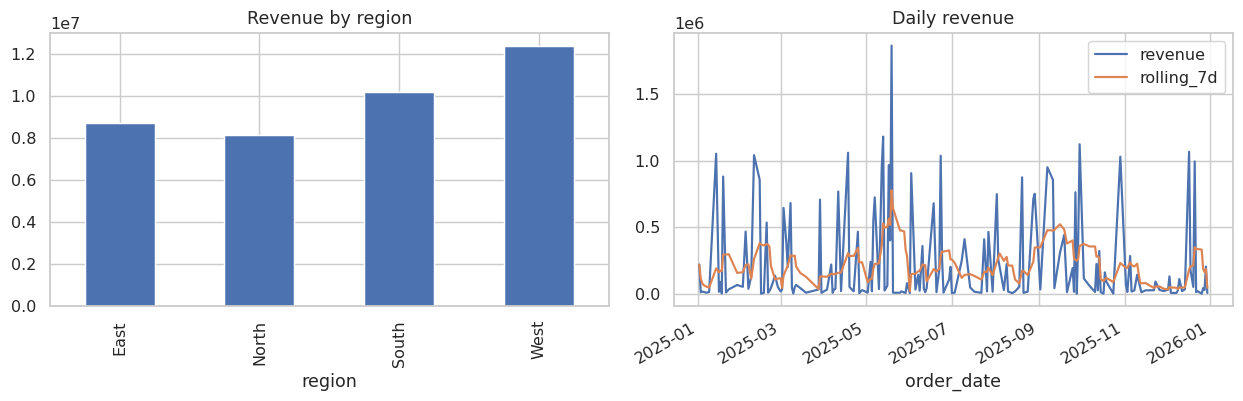

In [3]:
import pandas as pd, matplotlib.pyplot as plt
sales=pd.read_csv(DATA/"sales.csv",parse_dates=["order_date"]); customers=pd.read_csv(DATA/"customers.csv")
assert sales.order_id.is_unique and customers.customer_id.is_unique
df=sales.merge(customers,on="customer_id",validate="many_to_one")
df["profit_margin"]=df.profit/df.revenue
summary=df.groupby(["region","segment"]).agg(orders=("order_id","nunique"),revenue=("revenue","sum"),profit=("profit","sum"),units=("units","sum")).reset_index()
daily=df.groupby("order_date").revenue.sum().sort_index().to_frame("revenue"); daily["rolling_7d"]=daily.revenue.rolling(7,min_periods=1).mean()
print("Overall revenue:",df.revenue.sum(),"profit:",df.profit.sum(),"margin:",df.profit.sum()/df.revenue.sum()); display(summary)
fig,axes=plt.subplots(1,2,figsize=(12,4)); df.groupby("region").revenue.sum().plot(kind="bar",ax=axes[0],title="Revenue by region"); daily.plot(ax=axes[1],title="Daily revenue"); plt.tight_layout(); plt.show()
summary.to_csv("capstone_segment_summary.csv",index=False); daily.to_csv("capstone_daily_metrics.csv")

## Extension challenge

Extend the project with a monthly cohort view, customer retention definition, forecast baseline, model monitoring plan, automated quality tests, and a Streamlit application. State which conclusions are descriptive, predictive, or causal—and justify each label.

## Further reading

- Pandas merge: https://pandas.pydata.org/docs/user_guide/merging.html
- Scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
- Streamlit docs: https://docs.streamlit.io/

## Completion checklist

- [ ] I can explain the topic without reading the cells.
- [ ] I can reproduce the examples from a clean kernel.
- [ ] I completed each task and checked the reference solution.
- [ ] I tested an edge case.
- [ ] I can describe at least one limitation or risk.